# Live worker activity inference

Three ways to run, set in the settings cell:
- **`TRACKER = None`**: detection only. Tracking is bypassed; each box shows the class and detection confidence
  (`person 87%`). No IDs across frames, so no LLM either.
- **`DISABLE_CLASSIFY = True`**: detection + tracking, no LLM calls. Each ID gets its own colour and a trail of its
  recent path (`id 3 person 87%`), so you can tune the detector/tracker and spot ID switches (a person changing colour = new ID).
- **`DISABLE_CLASSIFY = False`** (default): tracking + a vision LLM every `LLM_INTERVAL_S` seconds. Boxes are
  **green = working, red = idle, grey = pending/unknown**, labelled `3 WORKING sewing | person 87%`; labels lag ~3 s
  because the model answers in the background.

Edit the settings cell, re-run it, then re-run the live cell. Stop early with **Interrupt (■)**; results are kept.

**Kernel:** `../worker-activity-tracker/.venv` (VS Code asks once to install `ipykernel` into it).


In [1]:
import os, sys, json, time
from pathlib import Path

# Run from the project root so `wat` imports and relative paths resolve.
ROOT = Path.cwd() if (Path.cwd() / "wat").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import cv2, requests, pandas as pd
from IPython.display import display, Image, Markdown
from wat.config import load_config
from wat.pipeline import run

print("YOLO weights on disk:")
for p in sorted([*Path("models").glob("*.pt"), *Path("../worker-activity-tracker").glob("*.pt")]):
    print("  ", p)

YOLO weights on disk:
   ../worker-activity-tracker/yolo11l-pose.pt
   ../worker-activity-tracker/yolo11m-pose.pt
   ../worker-activity-tracker/yolo11s-pose.pt
   ../worker-activity-tracker/yolo11x-pose.pt
   models/yolo11n.pt


## Settings

In [32]:
# ---- what to run --------------------------------------------------------------------------
DISABLE_CLASSIFY = False           # True = boxes only, no LLM | False = boxes + LLM working/idle
SOURCE      = "data/video1.mp4"    # file, rtsp:// URL, or "0" for a webcam
REALTIME    = True                 # play files at real speed, like a live camera (False = as fast as possible)
MAX_SECONDS = None                 # stop after this much video time (None = whole video)
SAVE_VIDEO  = True                 # also write outputs/<video>[_tracking]/annotated.mp4
# DISPLAY_W   = 960                  # width of the live preview
# DISPLAY_W = 1920

# ---- detector (YOLO) ----------------------------------------------------------------------
WEIGHTS  = "models/yolo11n.pt"     # n = fastest on CPU. Pose models also work as person detectors, e.g.
                                   # "../worker-activity-tracker/yolo11s-pose.pt" (s/m/l/x: slower, finds more people)
DEVICE   = "cpu"                   # "cpu" (deployment target) or "cuda"
IMGSZ    = 960                    # inference size; larger finds small/far people, costs time (640 / 960 / 1280)
CONF     = 0.1                     # detection confidence threshold
DET_FPS  = 4.0                     # frames per second sent to detector + tracker (video fps is the upper bound)

# ---- tracker ------------------------------------------------------------------------------
TRACKER  = "bytetrack"             # bytetrack | botsort | ocsort | deepocsort | fasttrack | tracktrack, or a .yaml path
                                   # None = bypass tracking: detection only (forces DISABLE_CLASSIFY)
TRACKER_OVERRIDES = {              # any keys of that tracker's yaml; {} = use the file as is
    "track_high_thresh": 0.3,      # detections above this are matched first
    "track_low_thresh": 0.1,       # second-stage matching for weak detections (occluded people)
    "new_track_thresh": 0.35,      # min confidence to start a new ID
    "track_buffer": 20,            # processed frames a lost ID is kept (20 at 4 fps = 5 s)
    "match_thresh": 0.85,          # higher = more lenient matching (people move further between frames at low fps)
    # botsort/tracktrack only: "gmc_method": "sparseOptFlow",  # camera-motion compensation (moving camera, video3)
}
MIN_TRACK_AGE_S = 1.0              # classify: don't ask the LLM about IDs younger than this

# ---- LLM (only when classifying) --------------------------------------------------------------
BACKEND        = "ollama"          # "ollama" | "dummy" (random answers, no server)
MODEL          = "qwen3.5:4b"      # any vision model pulled in Ollama
LLM_INTERVAL_S = 2.0               # one decision per frame every N s (2.0 = 0.5 fps). Slower answers skip ticks.
LAYOUT         = "sheet"           # "sheet" = frame + 1 contact sheet (2 images) | "per_worker" = 1 + N images
IDLE_AFTER     = 2                 # consecutive idle answers before a worker turns Idle
WORK_AFTER     = 1                 # consecutive working answers before a worker turns Working
# --------------------------------------------------------------------------------------------

CLASSIFY = not DISABLE_CLASSIFY and TRACKER is not None
if not DISABLE_CLASSIFY and TRACKER is None:
    print("TRACKER = None: working/idle needs stable IDs, so classification is off")

cfg = load_config()
det, llm = cfg["detector"], cfg["llm"]
det.update(weights=WEIGHTS, device=DEVICE, imgsz=IMGSZ, conf=CONF, fps=DET_FPS, tracker=TRACKER)
det["tracker_overrides"] = TRACKER_OVERRIDES
cfg["tracks"]["min_age_s"] = MIN_TRACK_AGE_S
llm.update(backend=BACKEND if CLASSIFY else "none", interval_s=LLM_INTERVAL_S, layout=LAYOUT)
llm["ollama"]["model"] = MODEL
cfg["smoothing"].update(idle_after=IDLE_AFTER, work_after=WORK_AFTER)
cfg["output"]["annotated_video"] = SAVE_VIDEO
SRC = int(SOURCE) if str(SOURCE).isdigit() else SOURCE

cap = cv2.VideoCapture(SRC)
src_fps, n = cap.get(cv2.CAP_PROP_FPS) or 25.0, cap.get(cv2.CAP_PROP_FRAME_COUNT)
size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
cap.release()
stride = max(1, round(src_fps / DET_FPS))
print(f"{SOURCE}: {size[0]}x{size[1]} @ {src_fps:.1f} fps, {n / src_fps if n > 0 else float('nan'):.1f} s")
mode = "classify" if CLASSIFY else "track" if TRACKER else "detect only"
print(f"mode={mode} | detector {Path(WEIGHTS).name} on {DEVICE}, imgsz {IMGSZ}, conf {CONF}, "
      f"every {stride} frame(s) = {src_fps / stride:.2f} fps | tracker {TRACKER}"
      + (f" | LLM {BACKEND} {MODEL if BACKEND == 'ollama' else ''} every {LLM_INTERVAL_S}s" if CLASSIFY else ""))

data/video1.mp4: 1920x1080 @ 6.0 fps, 17.0 s
mode=classify | detector yolo11n.pt on cpu, imgsz 960, conf 0.1, every 2 frame(s) = 3.00 fps | tracker bytetrack | LLM ollama qwen3.5:4b every 2.0s


## Check the model server (when classifying)

Confirms Ollama is up and the model is pulled, then loads it with the same settings the live calls use.

In [33]:
if CLASSIFY and BACKEND == "ollama":
    from wat.llm import make_backend
    base = llm["ollama"]["base_url"].rstrip("/")
    try:
        names = [m["name"] for m in requests.get(f"{base}/api/tags", timeout=5).json()["models"]]
    except requests.RequestException as e:
        raise SystemExit(f"Ollama is not reachable at {base}. Start it with `ollama serve`. ({e})")
    if MODEL not in names:
        raise SystemExit(f"{MODEL} is not pulled. Run `ollama pull {MODEL}`. Available: {names}")
    print(f"{MODEL} loaded in {make_backend(llm).warm_up():.1f}s")
else:
    print("no model server needed for", "the dummy backend" if CLASSIFY else "no LLM")

qwen3.5:4b loaded in 0.2s


## Live

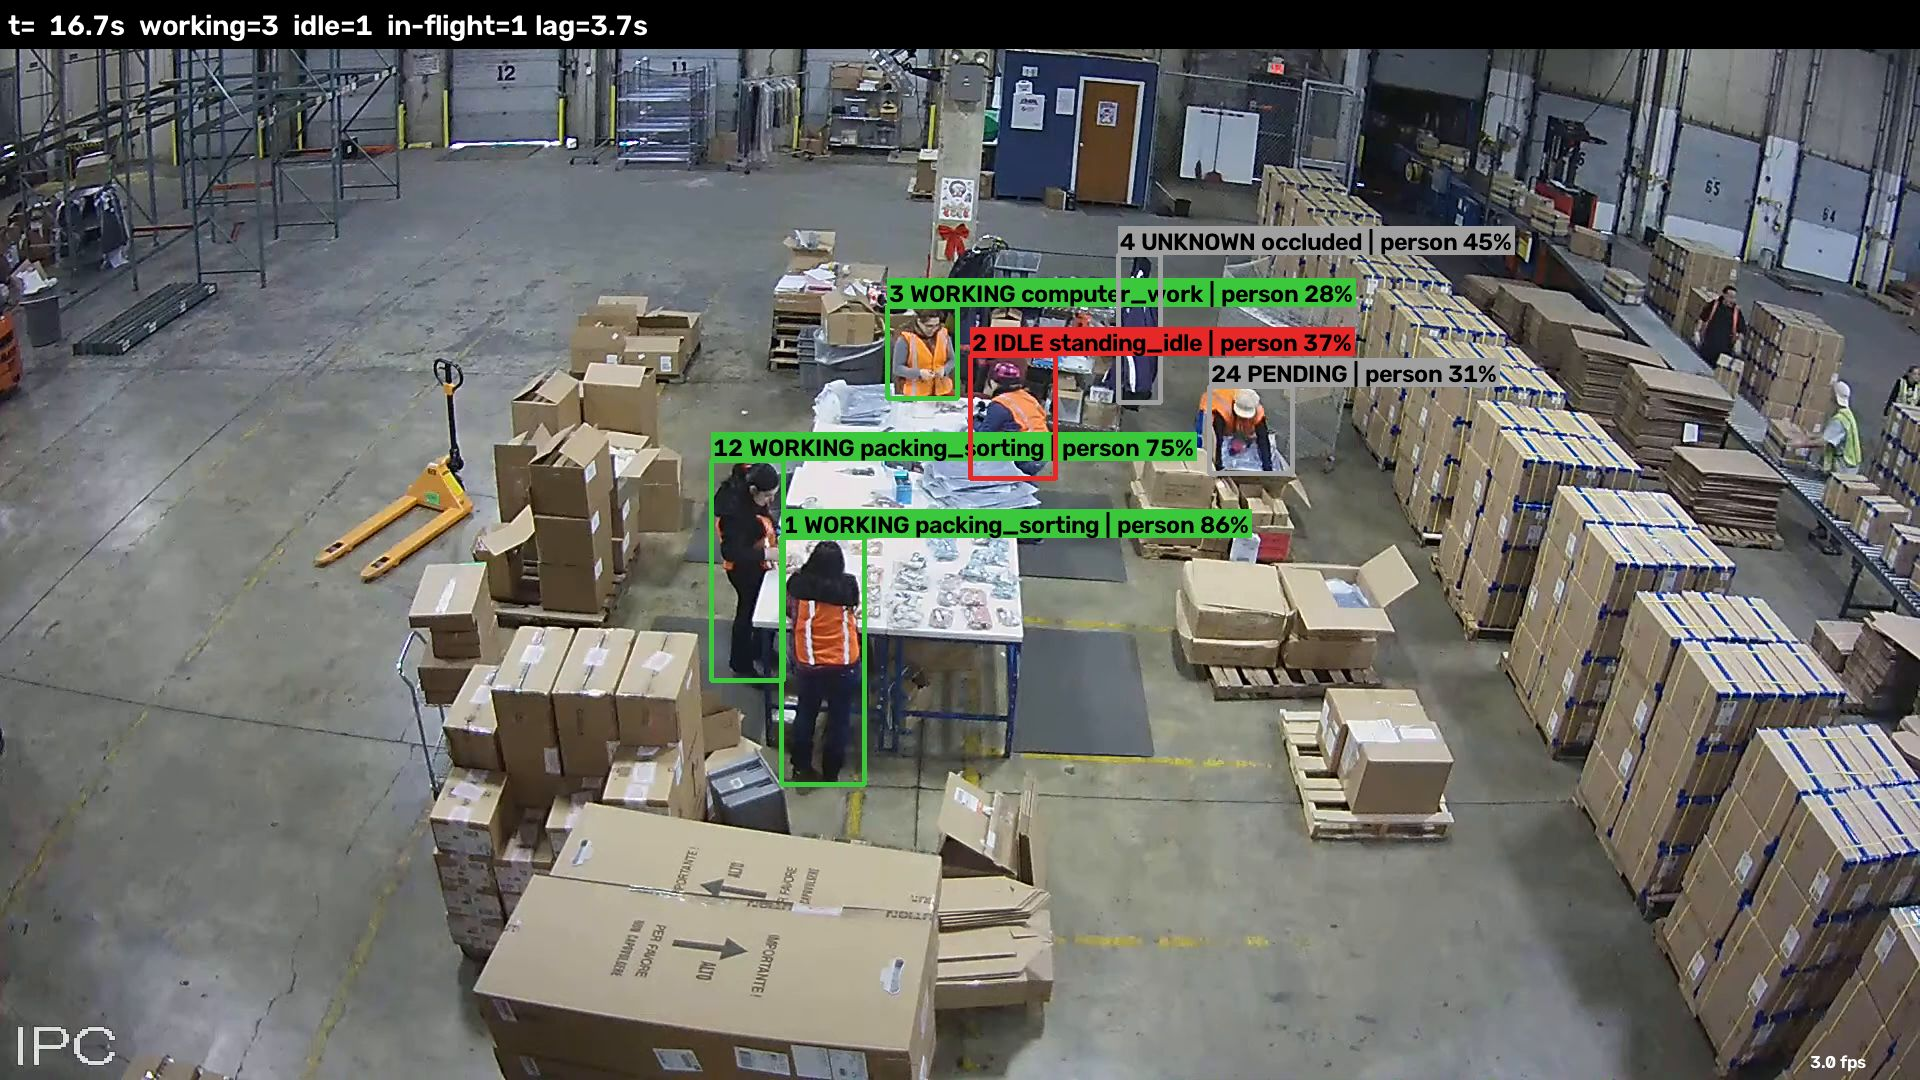

{
  "source": "data/video1.mp4",
  "video_s": 16.67,
  "interrupted": false,
  "wall_s": 17.34,
  "processed_fps": 2.94,
  "target_det_fps": 3.0,
  "tracker": "bytetrack",
  "backend": "ollama",
  "mean_people_per_frame": 5.31,
  "llm_calls": 4,
  "llm_errors": 0,
  "skipped_ticks": 4,
  "mean_latency_s": 3.49,
  "mean_label_lag_s": 3.33,
  "track_ids": 8
}


In [34]:
handle = display(Markdown("starting..."), display_id=True)
clock = {"last": time.perf_counter(), "fps": 0.0}

def show_frame(vis, t):
    now = time.perf_counter()
    clock["fps"] = 0.9 * clock["fps"] + 0.1 / max(now - clock["last"], 1e-6)
    clock["last"] = now
    h, w = vis.shape[:2]
    small = cv2.resize(vis, (DISPLAY_W, int(h * DISPLAY_W / w)), interpolation=cv2.INTER_AREA)
    cv2.putText(small, f"{clock['fps']:.1f} fps", (DISPLAY_W - 110, small.shape[0] - 12),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    ok, jpg = cv2.imencode(".jpg", small, [cv2.IMWRITE_JPEG_QUALITY, 80])
    handle.update(Image(data=jpg.tobytes()))

summary = run(SRC, cfg, realtime=REALTIME, max_seconds=MAX_SECONDS, on_frame=show_frame)
out_dir = Path(summary["output_dir"])
print(json.dumps(summary["run"], indent=2))

## Tracking quality

One row per ID. Signs of trouble: **many short-lived IDs** (fragmentation: lower `new_track_thresh`, raise
`track_buffer`), a **large `max_gap_s`** that was bridged (fine if it's the same person), or IDs that never get
many `frames` (flicker detections: raise `CONF`). `processed_fps` well below the target means the detector is too
slow for this device: lower `IMGSZ` or `DET_FPS`, or use a smaller model.

In [5]:
if not summary["tracks"]:
    print(f"no tracked IDs (tracker={TRACKER}) | detector ran at {summary['run']['processed_fps']} fps, "
          f"{summary['run']['mean_people_per_frame']} people per frame")
else:
    tracks = pd.DataFrame.from_dict(summary["tracks"], orient="index").rename_axis("track_id")
    tracks["duration_s"] = (tracks["last_s"] - tracks["first_s"]).round(2)
    print(f"{len(tracks)} IDs | detector ran at {summary['run']['processed_fps']} fps "
          f"(target {summary['run']['target_det_fps']}) | IDs shorter than 2 s: {(tracks['duration_s'] < 2).sum()}")
    display(tracks.sort_values("first_s"))

8 IDs | detector ran at 3.06 fps (target 3.0) | IDs shorter than 2 s: 1


,first_s,last_s,frames,max_gap_s,duration_s
track_id,,,,,
1,0.00,16.67,51,0.33,16.67
2,0.00,16.67,51,0.33,16.67
3,0.00,16.67,51,0.33,16.67
4,0.00,16.67,48,1.33,16.67
9,2.00,2.00,1,0.00,0.00
12,4.33,16.67,38,0.33,12.34
14,5.00,14.00,20,2.00,9.00
24,13.67,16.67,8,1.00,3.00


## Working / idle per worker (when classifying)

Seconds per state and % working (of the time the state was known). `unknown` = occluded, not a worker, or a failed call.

In [6]:
if CLASSIFY:
    workers = pd.DataFrame.from_dict(summary["workers"], orient="index").rename_axis("track_id")
    display(workers.sort_values("working_s", ascending=False))
    decisions = pd.read_csv(out_dir / "decisions.csv")
    display(decisions["activity"].value_counts().rename("answers"))
    display(decisions[["t", "track_id", "activity", "confidence", "raw_state", "state", "latency_s", "error"]].head(40))
    display(pd.read_csv(out_dir / "timeline.csv"))
else:
    print("no classification: set DISABLE_CLASSIFY = False (and a TRACKER) for working/idle results")

tracking only: set MODE = 'classify' for working/idle results


## What the model sees (when classifying)

Rebuilds the request at `AT_S` seconds: the frame with numbered boxes and the contact sheet of `[~2 s ago | now]`
pairs. Set `ASK = True` to also send it once and print the answer.

Full frame with numbered worker boxes.


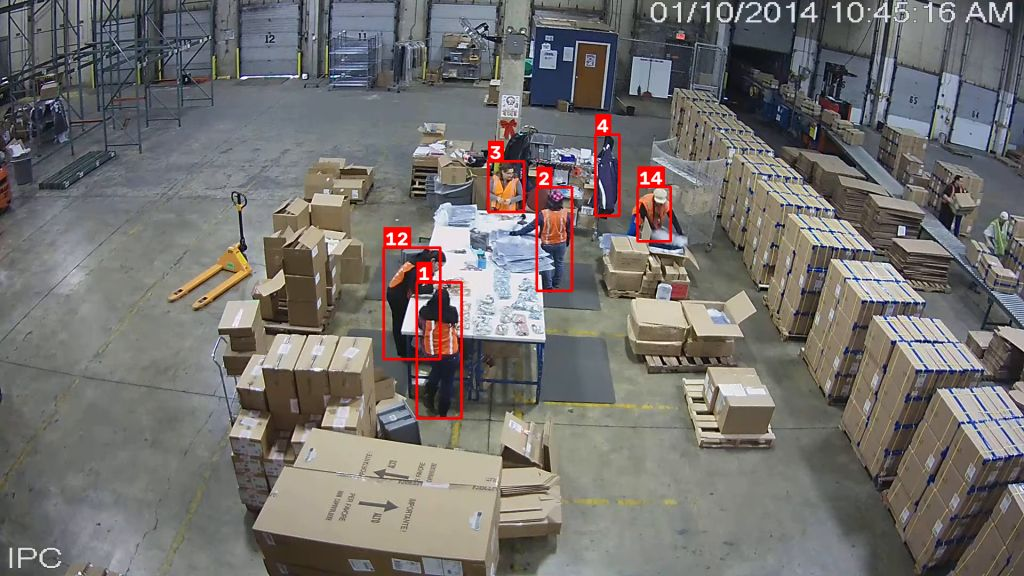

Close-ups of workers 1, 2, 3, 4, 12, 14, each labelled with its id.


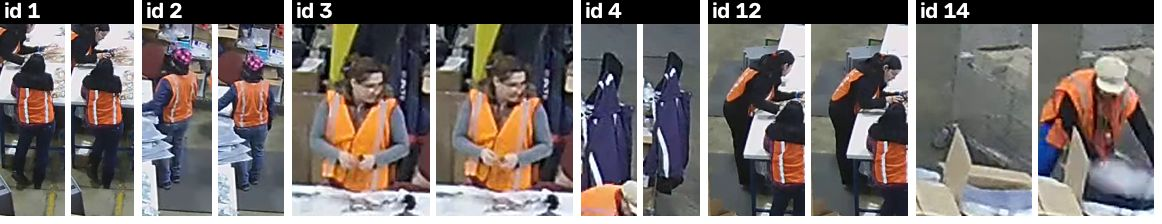

latency 3.9s | error: None


,track_id,activity,state,confidence,reason
0,1,packing_sorting,working,None,
1,2,walking_empty_handed,idle,None,
2,3,standing_idle,idle,None,
3,4,occluded,unknown,None,
4,12,packing_sorting,working,None,
5,14,carrying,working,None,


In [35]:
if CLASSIFY:
    from wat.preview import preview_request
    from wat.llm import make_backend
    AT_S, ASK = 6.0, True
    req = preview_request(SRC if isinstance(SRC, str) else "data/video1.mp4", AT_S, cfg)
    if req is None:
        print("no tracked workers at that time")
    else:
        for caption, jpg in req.images:
            print(caption)
            display(Image(data=jpg))
        if ASK:
            res = make_backend(llm).classify(req)
            print(f"latency {res.latency_s:.1f}s | error: {res.error}")
            display(pd.DataFrame([vars(d) for d in res.decisions.values()]))